#### Teoría de Circuitos II - UTN.BA

# Tarea Semanal 10
#### Autor: Rodríguez Silvosa, Martín
#### Docentes: LLamedo, Mariano ; Moharos, David

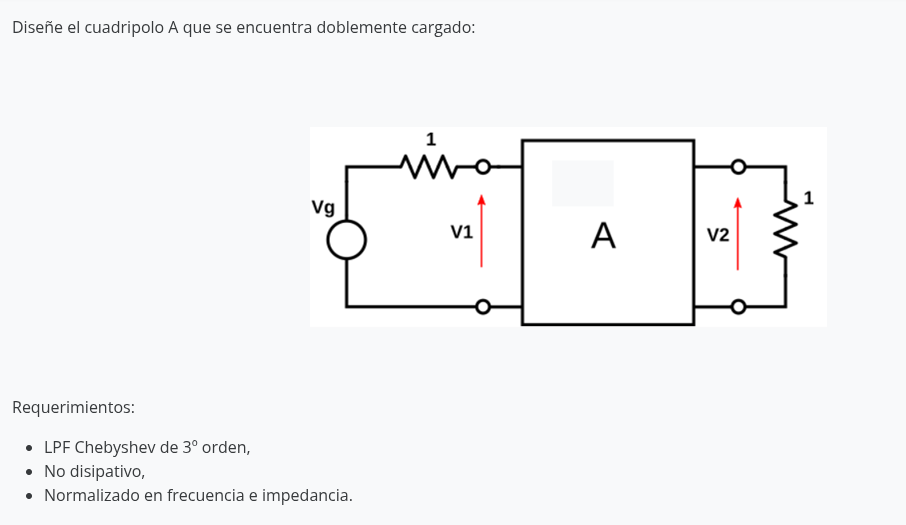
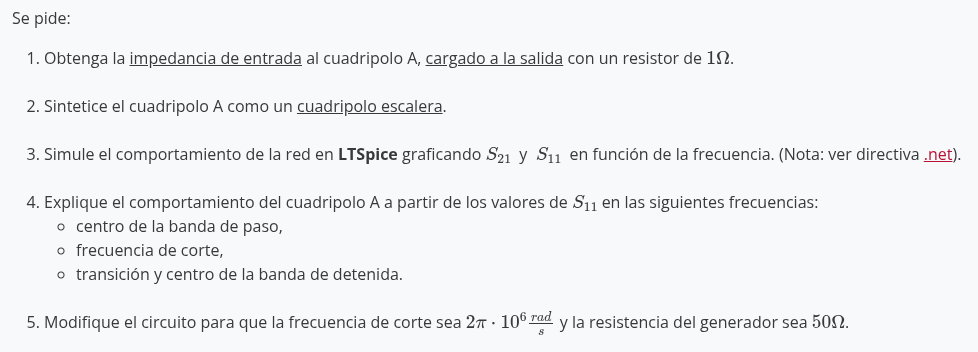

#### Importo de Python:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from pytc2.general import a_equal_b_latex_s, print_latex, s, symbfunc2tf
from pytc2.sistemas_lineales import bodePlot
from scipy import signal as sig

sp.init_printing()
s = sp.Symbol('s')

# Desarrollo manuscrito:
Esta vez no llego a dejarlo lindo:

In [7]:
from IPython.display import IFrame
#IFrame("archivo.pdf", width=900, height=600)
IFrame("ts10_1.pdf", width=1000, height=1000)

#### - Se diseñó la transferencia pasa bajos de orden 3 Chevyshev
#### - Se aplicó como requisito para la síntesis del cuadripolo doblemente cargado
#### - Se sintetizó el circuito escalera no discipativo normalizado


$$
Z_1 = \frac{2 s³ + s² + 2 s + \frac{1}{2}}{s² + \frac{1}{2} s + \frac{1}{2}}
$$

### Chevyshev Nº 3 obtenido:

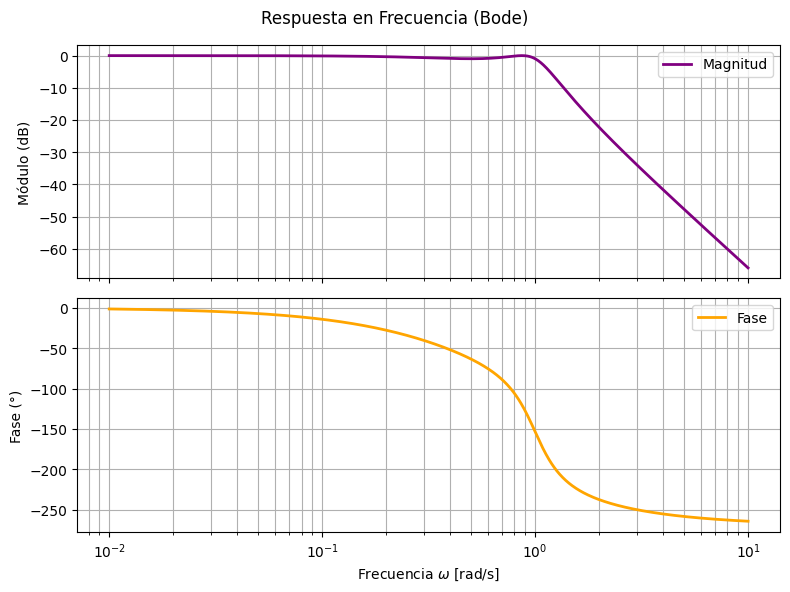

In [2]:
# Defino la transferencia : 
num = [1/2]
den = [1, 1, 5/4, 1/2]
H = sig.TransferFunction(num, den)

w = np.logspace(-2, 1, 1000)   # de 0.01 a 10 rad/s

w_bode, H_mag, H_phase = sig.bode(H, w=w)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
fig.suptitle("Respuesta en Frecuencia (Bode)")

ax1.semilogx(w_bode, H_mag, color="purple", lw=2, label="Magnitud")
ax1.set_ylabel("Módulo (dB)")
ax1.grid(True, which="both")
ax1.legend()

ax2.semilogx(w_bode, H_phase, color="orange", lw=2, label="Fase")
ax2.set_ylabel("Fase (°)")
ax2.set_xlabel("Frecuencia $\omega$ [rad/s]")
ax2.grid(True, which="both")
ax2.legend()

plt.tight_layout()
plt.show()

## Simulación de $S_{11}$ :

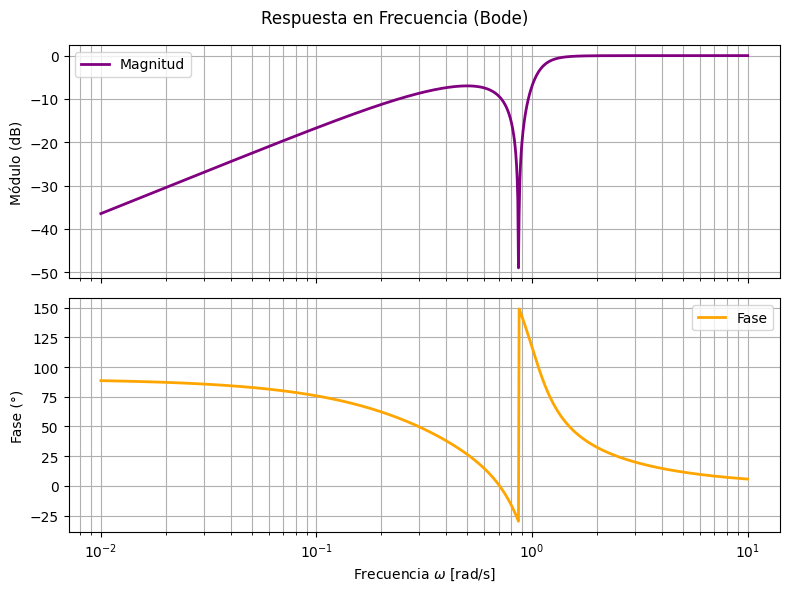

In [8]:
# Defino la transferencia : 
num = [1, 0, 3/4, 0]
den = [1, 1, 5/4, 1/2]
H = sig.TransferFunction(num, den)

w = np.logspace(-2, 1, 1000)   # de 0.01 a 10 rad/s

w_bode, H_mag, H_phase = sig.bode(H, w=w)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
fig.suptitle("Respuesta en Frecuencia (Bode)")

ax1.semilogx(w_bode, H_mag, color="purple", lw=2, label="Magnitud")
ax1.set_ylabel("Módulo (dB)")
ax1.grid(True, which="both")
ax1.legend()

ax2.semilogx(w_bode, H_phase, color="orange", lw=2, label="Fase")
ax2.set_ylabel("Fase (°)")
ax2.set_xlabel("Frecuencia $\omega$ [rad/s]")
ax2.grid(True, which="both")
ax2.legend()

plt.tight_layout()
plt.show()

## Verificación
### $|S_{21}|² + |S_{11}|² = 1$ :

S_11(s) =


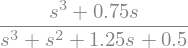

S11(s) =


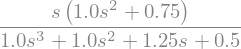

S_21(s) =


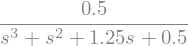

S21(s) =


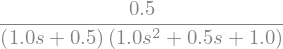

|S_{21}|^2 + |S_{11}|^2 =


In [16]:
Z_numerador = 2*s**3 + s**2 + 2*s + (1/2)
Z_denominador = s**2 + (1/2)*s + (1/2)
Z_1 = Z_numerador / Z_denominador

S_11_numerador = s**3 + (3/4)*s
S_11_denominador = s**3 + s**2 + (5/4)*s + (1/2)
S_11 = S_11_numerador / S_11_denominador

S_21_numerador = (1/2)
S_21_denominador = s**3 + s**2 + (5/4)*s + (1/2)
S_21 = S_21_numerador / S_21_denominador

print("S_11(s) =")
display(S_11)

S_11 = sp.simplify(S_11)
S_11 = sp.together(S_11)
S_11 = sp.factor(S_11)
S_11 = sp.simplify(S_11)

print("S11(s) =")
display(S_11)

print("S_21(s) =")
display(S_21)

S_21 = sp.simplify(S_21)
S_21 = sp.together(S_21)
S_21 = sp.factor(S_21)
S_21 = sp.simplify(S_21)

print("S21(s) =")
display(S_21)

suma = sp.simplify(S_11*S_11.subs(s, -s) + S_21*S_21.subs(s, -s))
print(r"|S_{21}|^2 + |S_{11}|^2 =")
display(suma)   # Tiene que dar 1

## Simulaciones en LTSpice, circuito sintetizado:

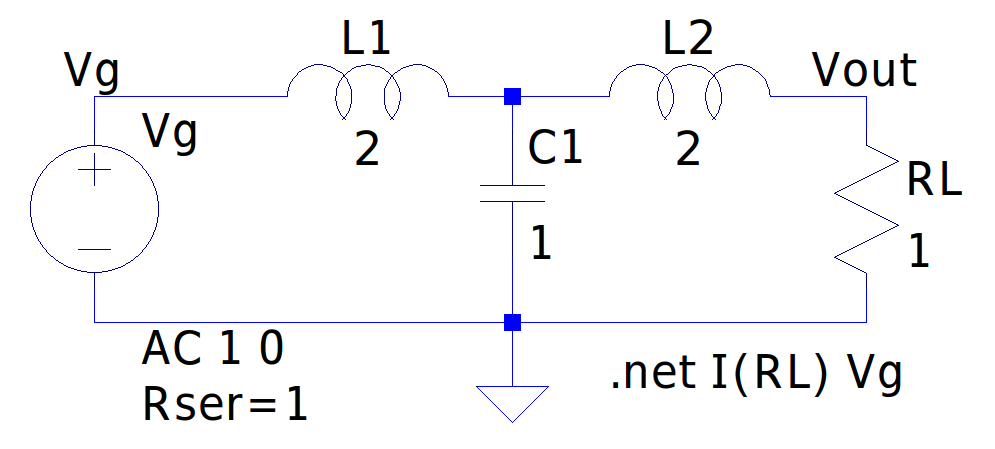

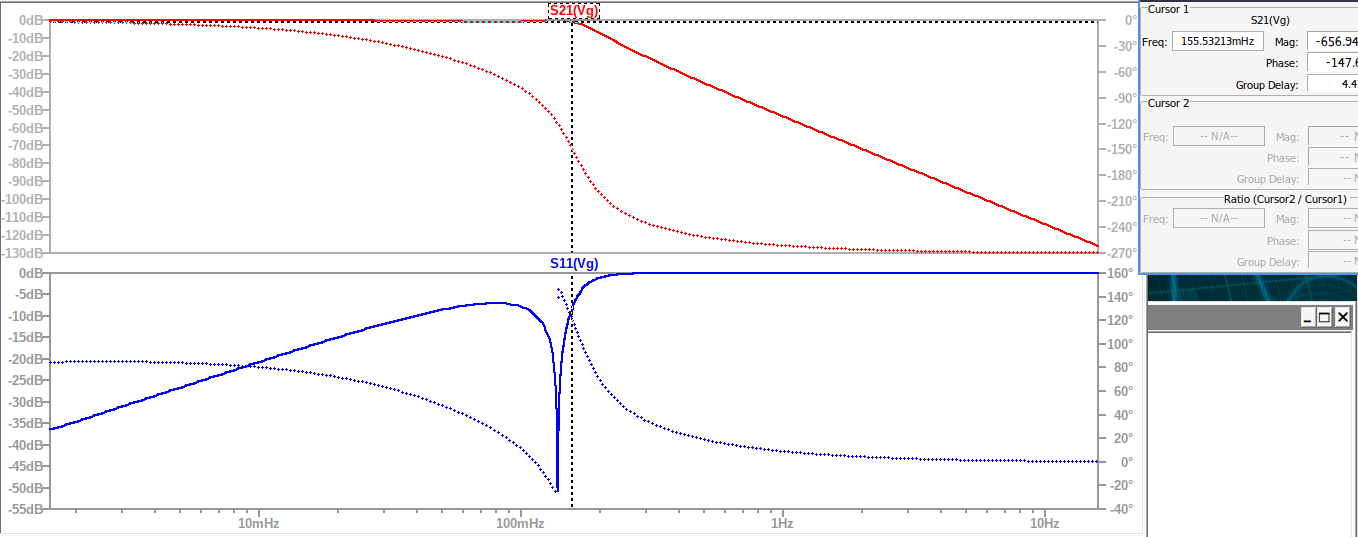

### Análisis de $S_{11}$ :

#### - Banda de paso: La potencia reflejada tiende a 0 durante la mayoría de la banda de paso, aumentando a medida que llega a la frecuencia de corte.
#### - Frecuencia de corte: a partir de acá la potencia reflejada empieza a superar a la transmitida luego de un salto de fase.
#### - Transición y centro de la banda de detenida: La potencia reflejada empieza a subir rápidamente e iguala a la transmitida, para luego seguir creciendo y terminar rápidamente reflejando toda la potencia transmitida.

### Desnormalización:

$$
Rg_N \cdot \Omega_z = 50\Omega
$$
$$
\Omega_z = 50
$$
$$
\Omega_{\omega} = 2 \pi \ 10⁶
$$
$$
C1 = \frac{C1_N}{\Omega_z \cdot \Omega_{\omega}} = \frac{1}{50 \cdot 2 \pi \cdot 10000000} = 3.183 nF
$$
$$
L2 = L1 = \frac{L1_N \cdot \Omega_z}{\Omega_{\omega}} = \frac{2 \cdot 50}{2 \pi \cdot 10000000} = 15.915 \  \mu Hy
$$

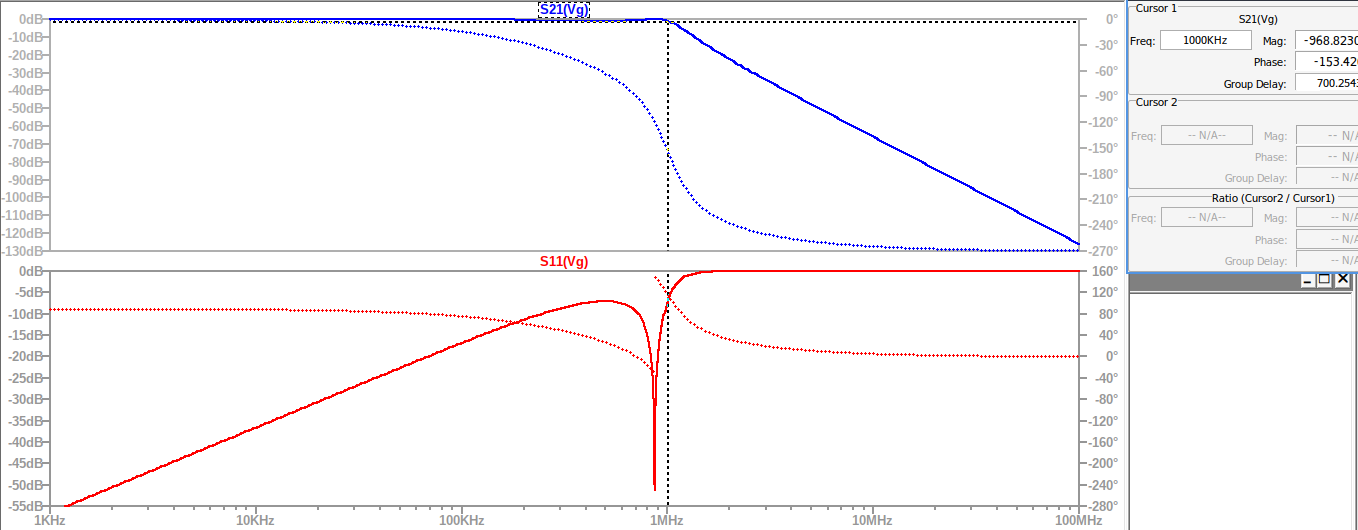

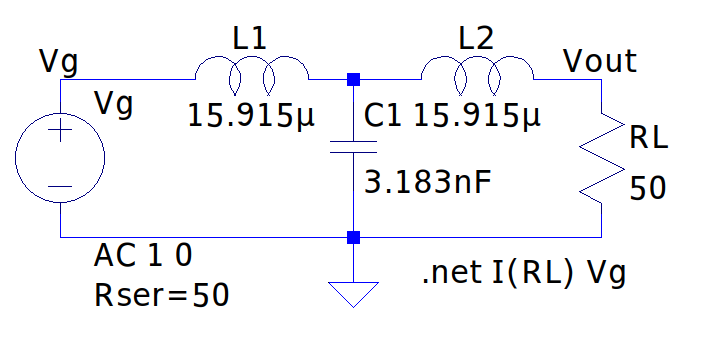